In [2]:
import copy
import csv
from docplex.mp.model import Model
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd



### Setup

In [48]:
df = pd.read_csv('data1.csv')
print(df)

   index  x_pickup  y_pickup  x_dest  y_dest  robots_required
0      0         0         0       0       0                0
1      1         0       100       0     100                1
2      2       100       100     100     100                1
3      3       100         0     100       0                1


In [49]:
df

,index,x_pickup,y_pickup,x_dest,y_dest,robots_required
0,0,0,0,0,0,0
1,1,0,100,0,100,1
2,2,100,100,100,100,1
3,3,100,0,100,0,1


IndexError: list index out of range

In [14]:
NODE_TYPE = {
    0:'DEPOT',
    1:'PICKUP',
    2:'DESTINATION'
}

class Node:
    def __init__(self,coor,task, node_type):
        self.coor = coor
        self.task_idx = task
        self.node_type = node_type
        
    def __repr__(self):
        return f" {NODE_TYPE[self.node_type]} {self.coor} of task {self.task_idx}"


class Task:
    def __init__(self,pickup_coor, dest_coor,robots_required:int,index):
        self.pickup_coor = pickup_coor
        self.dest_coor = dest_coor
        self.n = robots_required
        if index is not None:
            self.index = index
        else:
            self.index = -1
    
    def __repr__(self):
        return f"Task {self.index},{self.pickup_coor},{self.dest_coor},{self.n}"
    
    def expand_nodes(self) -> tuple:
        expanded_pickups = [Node(self.pickup_coor,self.index, 1) for _ in range(self.n)]
        expanded_dests = [Node(self.dest_coor,self.index, 2) for _ in range(self.n)]
        return (expanded_pickups, expanded_dests)
        pass

In [92]:
def gen_tasks(num_tasks,max_robots, coor_range = 500, no_delivery = False):
    """
    if no-delivery = true then every tasks has their pick up node = their destination node.
    """
    tasks = []
    for i in range(1,num_tasks + 1): # index start from 1 because 0 is the depot
        pickup_coor = rnd.uniform(0, coor_range,2)
        if no_delivery ==True:
            dest_coor = pickup_coor
        else:
            dest_coor = rnd.uniform(0, coor_range,2)
        if max_robots !=1:
            total_robots_required = rnd.randint(1,max_robots)
        else:
            total_robots_required = 1
        cur_tasks = Task(pickup_coor, dest_coor, total_robots_required, i)
        tasks.append(cur_tasks)
    
    return tasks

def gen_depot(coor_range = 500):
    coor = rnd.uniform(0, coor_range,2)
    depot = Node(coor, 0, 0)
    return depot

def construct_v_prime(depot,tasks):
    v_prime = [depot]
    for task in tasks:
        cur_pickups, cur_dests = task.expand_nodes()
        v_prime += cur_pickups
        v_prime += cur_dests
    
    return v_prime

def add_node_index(v_prime):
    
    total_nodes = len(v_prime)
    for i in range(total_nodes):
        v_prime[i].index = i

    return v_prime

def update_connection(v_prime):
    """
    Note that v_prime must have indicies already
    """
    depot = v_prime[0]
    depot.connection = [node.index for node in v_prime if node.index != depot.index and node.node_type == 1]# depot
    for cur_node in v_prime[1:]:
        cur_task_idx =  cur_node.task_idx
        cur_type = cur_node.node_type
        if cur_type == 1: #pickup
            cur_node.connection = [node.index for node in v_prime if node.task_idx == cur_task_idx and node.node_type ==2]
        elif cur_type == 2: #destination
            cur_node.connection = [node.index for node in v_prime if node.task_idx != cur_task_idx and node.node_type in [0,1]]
    return v_prime

def construct_e_prime(v_prime_connected):
    """
    Parameters
    ----------
    v_prime_connected: set of v_prime with info of connection
    """
    total_nodes = len(v_prime_connected)
    e_prime = {}
    e_prime ={
        i: v_prime_connected[i].connection for i in range(total_nodes)
    }
    return e_prime

def cal_dist(node1,node2):
    dist = np.linalg.norm(node1.coor - node2.coor)
    return dist

def create_cost_dict(connected_v_prime,node_idx_mapper):
    node_idx_mapper = {node.index: node for node in connected_v_prime}
    c = {}
    for cur_node in connected_v_prime:
        cur_idx = cur_node.index
        dist = {
            node_idx_mapper[node].index:cal_dist(cur_node,node_idx_mapper[node]) for node in cur_node.connection
        }
        c[cur_idx] = dist
    return c

def plot_map(depot, tasks):
    plt.scatter(depot.coor[0], depot.coor[1],c= 'C3', label = 'depot')
    for task in tasks:
        pickup_coor = task.pickup_coor
        dest_coor = task.dest_coor
        plt.scatter(pickup_coor[0], pickup_coor[1],c = 'C0',)
        plt.scatter(dest_coor[0], dest_coor[1], c ='C1',)
        xs = [pickup_coor[0],dest_coor[0]]
        ys = [pickup_coor[1],dest_coor[1]]
        plt.plot(xs, ys, c = PATH_COLOR[task.n])

    legends_path ={f"{i} robot(s)":Line2D([0],[0], color = f"C{i}",lw = 2) for i in range(1,R)}
    legends_node = {
        "depot" : Line2D([0], [0], marker='o', color='w',markerfacecolor='C3', markersize= 8),
        "pickup" : Line2D([0], [0], marker='o', color='w',markerfacecolor='C0', markersize= 8),
        "dest." : Line2D([0], [0], marker='o', color='w',markerfacecolor='C1', markersize= 8),
    }
    legends = dict(legends_path,**legends_node)
    plt.legend(legends.values(), legends.keys())
    plt.plot()
    
def get_data_from_csv(path):
    df = pd.read_csv(path)
    data_dict = df.to_dict(orient = 'records')
    depot_raw = data_dict.pop(0)
    depot = Node(np.array([depot_raw['x_pickup'], depot_raw['y_pickup']]),0,0)
    for task in data_dict:
        task['pickup_coor'] = np.array([task['x_pickup'],task['y_pickup']])
        task['dest_coor'] = np.array([task['x_dest'],task['y_dest']])
        to_remove = ('x_pickup', 'y_pickup', 'x_dest', 'y_dest')
        [task.pop(field) for field in to_remove]
    tasks = [Task(**data) for data in data_dict]
    return depot, tasks

In [98]:
seed_num =  15
rnd = np.random
rnd.seed(seed_num)

### Generate random variables

In [109]:
T = 20 # total tasks
R = 1# total robots
gen_tasks = False
data_path = 'data1.csv'
PATH_COLOR = {i: f'C{i}' for i in range(R+1)}

gap =0.1
time_limit = 1800
M = 10**6
indicator_methods = {
    1:"INDICATOR_CONSTRAINTS",
    2:"BIG_M_LAZY"
}
handle_indicator = 1

In [110]:
v_prime

[ DEPOT [0 0] of task 0,
  PICKUP [  0 100] of task 1,
  DESTINATION [  0 100] of task 1,
  PICKUP [100 100] of task 2,
  DESTINATION [100 100] of task 2,
  PICKUP [100   0] of task 3,
  DESTINATION [100   0] of task 3]

In [111]:
if gen_tasks == True: 
    depot = gen_depot()
    tasks = gen_tasks(T,R, no_delivery = True)
else:
    depot,tasks = get_data_from_csv(data_path)

v_prime = construct_v_prime(depot,tasks)
add_node_index(v_prime)
v_prime = update_connection(v_prime)
node_idx_mapper = {node.index: node for node in v_prime}
c = create_cost_dict(v_prime,node_idx_mapper)
e_prime = construct_e_prime(v_prime)

Pt = {task.index:[node.index for node in v_prime if (node.task_idx ==task.index and node.node_type ==1)] for task in tasks}
Dt = {task.index:[node.index for node in v_prime if (node.task_idx ==task.index and node.node_type ==2)] for task in tasks}

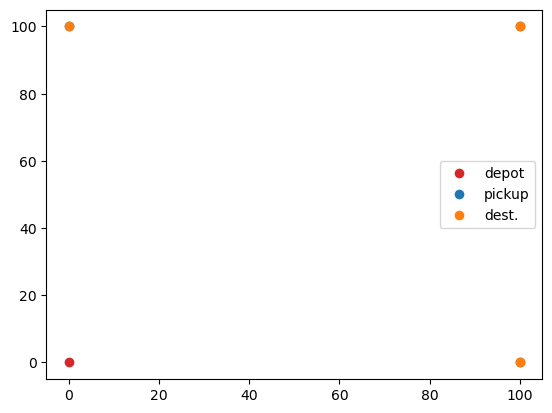

In [112]:
plot_map(depot, tasks)

## Implement the model and solve

In [113]:
model = Model("ThaoModel")
t_idx = [task.index for task in tasks]
i_idx = [node.index for node in v_prime]
# ij_idx = [(i.index,j.index) for i in v_prime for j in v_prime]
ij_idx = [(i.index,j) for i in v_prime for j in i.connection]
x= model.binary_var_dict(ij_idx, name = 'x')
y = model.continuous_var_dict(i_idx,lb =0, name = 'y')
z = model.continuous_var_dict(i_idx,lb = 0, name = 'z')

In [114]:
model.add_constraint(model.sum(x[0,j] for j in e_prime[0]) == R) #2
model.add_constraint(model.sum(x[i,0] for i in e_prime if 0 in e_prime[i]) == R) #3
model.add_constraints(model.sum(x[i,j] for i in e_prime if j in e_prime[i])==1 for j in i_idx[1:])
model.add_constraints(model.sum(x[i,j] for j in e_prime[i])==1 for i in i_idx[1:])
if handle_indicator ==1:
    indicator_SEC = [model.indicator_constraint(x[i,j],z[j] ==z[i]  +c[i][j] +y[j]) for i  in i_idx for j in e_prime[i] if j!=0]
    model.add_indicator_constraints(indicator_SEC)
    pass
elif handle_indicator ==2:
    model.add_lazy_constraints(z[j] + M*(1-x[i,j]) >= z[i] +c[i][j] + y[j] for i  in i_idx for j in e_prime[i] if j!=0)
    model.add_lazy_constraints(z[j] - M*(1-x[i,j]) <= z[i] +c[i][j] + y[j] for i  in i_idx for j in e_prime[i] if j!=0)
model.add_constraints(z[Pt[t][0]] == z[j] for t in t_idx for j in Pt[t])
model.add_constraints(z[Dt[t][0]] == z[j] for t in t_idx for j in Dt[t])
model.parameters.mip.tolerances.mipgap = gap
model.time_limit = time_limit
model.minimize(model.sum(c[i][j]*x[i,j] for i in i_idx for j in e_prime[i]) + model.sum(y[i.index] for i in v_prime))


In [115]:
print(model.export_as_lp())
sol = model.solve(log_output = True)

C:\Users\CTNGUY~1\AppData\Local\Temp\ThaoModel.lp
Version identifier: 22.1.0.0 | 2022-03-09 | 1a383f8ce
CPXPARAM_Read_DataCheck                          1
CPXPARAM_TimeLimit                               1800
CPXPARAM_MIP_Tolerances_MIPGap                   0.10000000000000001
Tried aggregator 2 times.
MIP Presolve eliminated 12 rows and 4 columns.
Aggregator did 3 substitutions.
Reduced MIP has 17 rows, 31 columns, and 66 nonzeros.
Reduced MIP has 12 binaries, 0 generals, 0 SOSs, and 9 indicators.
Presolve time = 0.00 sec. (0.05 ticks)
Found incumbent of value 10058.578644 after 0.00 sec. (0.14 ticks)
Probing time = 0.00 sec. (0.01 ticks)
Tried aggregator 1 time.
Detecting symmetries...
Reduced MIP has 17 rows, 31 columns, and 66 nonzeros.
Reduced MIP has 12 binaries, 0 generals, 0 SOSs, and 9 indicators.
Presolve time = 0.02 sec. (0.05 ticks)
Probing time = 0.00 sec. (0.01 ticks)
Clique table members: 8.
MIP emphasis: balance optimality and feasibility.
MIP search method: dynamic sea

### path each robots

## Illustration

In [116]:
def get_paths(moved_edges,total_robots):
    """
    Acquire the node sequence of each robot
    """
    left_edges = copy.deepcopy(moved_edges)
    paths = []
    for _ in range(total_robots):
        cur_path =[0]
        for edge in left_edges:
            if edge[0] ==0:
                cur_node = edge[1]
                cur_path.append(edge[1])
                left_edges.remove(edge)
                break

        while cur_node !=0:
            for edge in left_edges:
                if edge[0] == cur_node:
                    cur_node = edge[1]
                    cur_path.append(edge[1])
        paths.append(cur_path)
    
    return paths

def get_tasks_path(paths):
    """
    Acquire the task sequence for each robot
    """
    tasks_path = []
    for path in paths:
        task_path = [node_idx_mapper[node].task_idx for node in path]
        tasks_path.append(task_path)
    return tasks_path

def get_paths_coor(paths,node_idx_mapper):
    paths_coor = []
    for path in paths:
        xs = [node_idx_mapper[node].coor[0] for node in path]
        ys = [node_idx_mapper[node].coor[1] for node in path]
        cur_path_coors = [xs,ys]
        paths_coor.append(cur_path_coors)
    
    return paths_coor

In [117]:
sol_dict = sol.get_value_dict(x)
moved_edges = [path for path in sol_dict if sol_dict[path] ==1]
paths = get_paths(moved_edges,R)
tasks_path = get_tasks_path(paths)
paths_coor = get_paths_coor(paths,node_idx_mapper)

[]

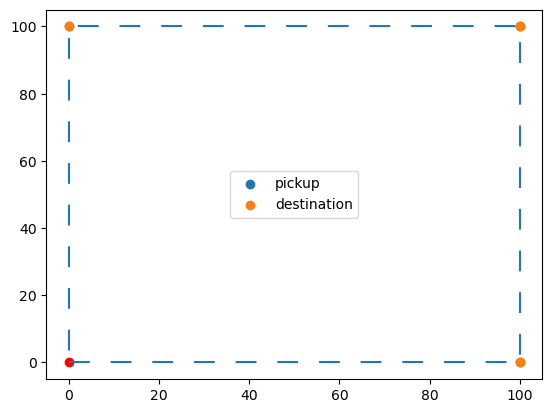

In [118]:
pickup_xs= [task.pickup_coor[0] for task in tasks]
pickup_ys = [task.pickup_coor[1] for task in tasks]
dest_xs = [task.dest_coor[0] for task in tasks]
dest_ys = [task.dest_coor[1] for task in tasks]
plt.scatter(depot.coor[0], depot.coor[1],c= 'red')
plt.scatter(pickup_xs,pickup_ys, label = 'pickup')
plt.scatter(dest_xs,dest_ys, label = 'destination')
i=0
for path_coor in paths_coor:
    plt.plot(path_coor[0],path_coor[1],linestyle = (0,(10-i,10)), color = f"C{i}")
    i+=1
plt.legend()
plt.plot()